# BÀI TẬP E3: MÔ HÌNH HỒI QUY (LSTM / GRU) TRÊN CHUỖI HÀNG ẢNH
**Trường Đại Học Bách Khoa TP.HCM (HCMUT)** — Khoa Khoa Học và Kỹ Thuật Máy Tính  
**Môn học:** CO5085 – Học Sâu và Ứng Dụng Trong Thị Giác Máy Tính (HK261)  
**Sinh viên:** Đinh Hoàng Duy Khánh (MSSV: 2670306) — **Nhóm:** Trailblazer  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/khanhhoangduydinh/CO5085-Deep_Learning_and_Its_Applications_in_Computer_Vision/blob/main/notebooks/e3_image_sequences.ipynb)

---


---
## Phần 1: Khởi Tạo Môi Trường & Import Thư Viện

Trước khi huấn luyện mô hình, chúng ta cần nạp các thư viện chuẩn trong hệ sinh thái Python và Deep Learning:
- **`torch` & `torch.nn`:** Thư viện Deep Learning cốt lõi của PyTorch, cung cấp cấu trúc dữ liệu Tensor và các lớp mạng nơ-ron (Linear, Conv2d, LSTM,...).
- **`torchvision` & `transforms`:** Cung cấp bộ dữ liệu thị giác máy tính chuẩn (`FashionMNIST`) và các hàm tiền xử lý / chuẩn hóa ảnh.
- **`torch.utils.data` (`DataLoader`, `Subset`):** Công cụ quản lý nạp dữ liệu theo từng lô (mini-batch) và chia tập dữ liệu.
- **`matplotlib.pyplot` & `seaborn`:** Thư viện vẽ đồ thị, trực quan hóa ảnh và vẽ ma trận nhầm lẫn (Confusion Matrix).
- **`sklearn.metrics` (`confusion_matrix`):** Đánh giá hiệu năng chi tiết trên từng lớp dự đoán.


In [1]:
# 1. Nạp các thư viện chuẩn của Python
import os          # Tương tác với hệ điều hành và biến môi trường
import math        # Các hàm toán học cơ bản (căn bậc hai, số pi,...)
import time        # Đo đạc thời gian huấn luyện từng mô hình
import random      # Sinh số ngẫu nhiên của Python
from pathlib import Path  # Xử lý đường dẫn file/thư mục một cách trực quan

# 2. Nạp các thư viện tính toán khoa học và Deep Learning
import numpy as np          # Thư viện tính toán ma trận mảng số học
import torch               # Thư viện PyTorch cốt lõi
from torch import nn       # Mô-đun chứa các tầng mạng nơ-ron (Linear, Conv2d, ReLU,...)
from torch.utils.data import DataLoader, Subset  # Bộ nạp dữ liệu theo mini-batch và tập con
from torchvision import datasets, transforms     # Bộ dữ liệu thị giác và các phép biến đổi ảnh

# 3. Nạp thư viện vẽ biểu đồ và đánh giá
import matplotlib.pyplot as plt  # Thư viện vẽ biểu đồ chính
import seaborn as sns           # Thư viện vẽ biểu đồ nhiệt (Heatmap) đẹp mắt
from sklearn.metrics import confusion_matrix  # Hàm tính ma trận nhầm lẫn

# 4. Kiểm tra và thiết lập phần cứng (GPU CUDA hoặc CPU)
# Nếu bạn chạy trên Google Colab có bật GPU T4, DEVICE sẽ tự động là 'cuda'
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--> Thiết bị đang sử dụng để huấn luyện: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"--> Tên GPU: {torch.cuda.get_device_name(0)}")


--> Thiết bị đang sử dụng để huấn luyện: cuda
--> Tên GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


---
## Phần 2: Cố Định Random Seed và Tải Tập Dữ Liệu Fashion-MNIST

### 2.1. Tại sao phải cố định Random Seed?
Trong Machine Learning, các thao tác như **khởi tạo trọng số ngẫu nhiên** và **xáo trộn dữ liệu (shuffling)** phụ thuộc vào bộ sinh số giả ngẫu nhiên. Nếu không cố định seed, mỗi lần chạy code sẽ cho ra kết quả khác nhau. Cố định `SEED = 42` giúp:
- Kết quả hoàn toàn **tái lập được (reproducible)**.
- So sánh công bằng giữa các mô hình (mọi mô hình đều học trên cùng một tập ảnh và cùng thứ tự).

### 2.2. Phân chia tập dữ liệu theo đúng đề bài:
Tập **Fashion-MNIST** gồm các ảnh đơn sắc (grayscale) kích thước $28 	imes 28$ thuộc 10 lớp trang phục:
- **Tập Train chính thức (60,000 ảnh):** Được chia theo tỷ lệ 80/20 thành:
  - **48,000 ảnh Huấn luyện (Training set):** Dùng để cập nhật trọng số mô hình.
  - **12,000 ảnh Kiểm định (Validation set):** Dùng để theo dõi hiện tượng quá khớp (overfitting) và chọn mô hình tốt nhất sau mỗi epoch.
- **Tập Test chính thức (10,000 ảnh):** Giữ nguyên độc lập tuyệt đối, chỉ dùng để đánh giá mô hình sau cùng một lần duy nhất.


In [2]:
# Hằng số cấu hình toàn cục
SEED = 42              # Hạt giống ngẫu nhiên cố định
DATA_FOLDER = Path("data")  # Thư mục lưu trữ dữ liệu Fashion-MNIST

# Tên 10 lớp trang phục tương ứng với các nhãn số từ 0 đến 9
CLASS_NAMES = [
    "T-shirt/top",  # 0: Áo thun
    "Trouser",      # 1: Quần dài
    "Pullover",     # 2: Áo len chui đầu
    "Dress",        # 3: Váy liền
    "Coat",         # 4: Áo khoác
    "Sandal",       # 5: Giày xăng-đan
    "Shirt",        # 6: Áo sơ mi
    "Sneaker",      # 7: Giày thể thao
    "Bag",          # 8: Túi xách
    "Ankle boot",   # 9: Ủng cao cổ
]


def set_seed(seed=SEED):
    """Hàm thiết lập seed cho tất cả các bộ sinh số ngẫu nhiên."""
    random.seed(seed)                   # Cố định thư viện random chuẩn
    np.random.seed(seed)                # Cố định thư viện NumPy
    torch.manual_seed(seed)             # Cố định PyTorch trên CPU
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed) # Cố định PyTorch trên tất cả GPU CUDA


def make_split_indices(total=60_000, seed=SEED):
    """Tạo danh sách chỉ số phân chia 80% train (48,000) và 20% validation (12,000)."""
    # Dùng Generator có seed cố định để việc xáo trộn chỉ số luôn ra cùng kết quả
    generator = torch.Generator().manual_seed(seed)
    ids = torch.randperm(total, generator=generator).tolist()
    split = int(total * 0.8) # Điểm cắt 80% (48,000)
    return ids[:split], ids[split:]


def get_loaders(batch_size=256):
    """Tải dữ liệu Fashion-MNIST và trả về 3 DataLoader: Train, Validation, Test."""
    # Chuỗi biến đổi ảnh:
    # 1. ToTensor(): Chuyển ảnh PIL (0-255) thành Tensor float (0.0 - 1.0)
    # 2. Normalize((0.5,), (0.5,)): Chuẩn hóa về khoảng [-1.0, 1.0] qua công thức: (x - mean) / std
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    # Tải tập huấn luyện gốc (60,000 ảnh)
    full_train = datasets.FashionMNIST(DATA_FOLDER, train=True, download=True, transform=transform)
    # Tải tập kiểm tra gốc (10,000 ảnh)
    test_data = datasets.FashionMNIST(DATA_FOLDER, train=False, download=True, transform=transform)

    # Lấy chỉ số chia 48k / 12k
    train_ids, validation_ids = make_split_indices(len(full_train), seed=SEED)

    # Cấu hình nạp dữ liệu
    options = {
        "batch_size": batch_size,
        "num_workers": 0, # num_workers=0 tương thích hoàn hảo mọi môi trường (Colab/Windows/Linux)
        "pin_memory": torch.cuda.is_available()
    }

    # Tạo 3 DataLoader riêng biệt
    train_loader = DataLoader(Subset(full_train, train_ids), shuffle=True, **options)
    validation_loader = DataLoader(Subset(full_train, validation_ids), shuffle=False, **options)
    test_loader = DataLoader(test_data, shuffle=False, **options)

    return train_loader, validation_loader, test_loader


# Khởi tạo và nạp dữ liệu ngay
set_seed()
train_loader, validation_loader, test_loader = get_loaders(batch_size=256)
print(f"Số lượng mẫu huấn luyện (Train): {len(train_loader.dataset)}")
print(f"Số lượng mẫu kiểm định (Validation): {len(validation_loader.dataset)}")
print(f"Số lượng mẫu kiểm tra (Test): {len(test_loader.dataset)}")


Số lượng mẫu huấn luyện (Train): 48000
Số lượng mẫu kiểm định (Validation): 12000
Số lượng mẫu kiểm tra (Test): 10000


---
## Phần 3: Trực Quan Hóa Dữ Liệu Mẫu

Chúng ta hãy lấy 6 ảnh từ tập dữ liệu và hiển thị lên đồ thị để xem dạng ảnh của Fashion-MNIST.
Mỗi ảnh có kích thước $1 	imes 28 	imes 28$ (1 kênh màu xám, chiều cao 28, chiều rộng 28).


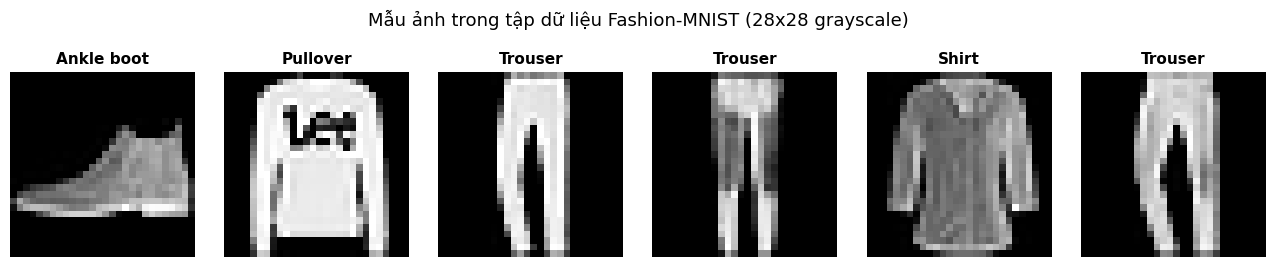

In [3]:
# Lấy thử một batch ảnh đầu tiên từ test_loader
images_batch, labels_batch = next(iter(test_loader))

# Tạo khung ảnh vẽ 6 cột
fig, axes = plt.subplots(1, 6, figsize=(13, 2.5))
for i in range(6):
    img = images_batch[i].squeeze().numpy() # Loại bỏ chiều kênh 1 để còn mảng 28x28
    label = labels_batch[i].item()           # Lấy nhãn số
    axes[i].imshow(img, cmap="gray")         # Hiển thị ảnh thang độ xám
    axes[i].set_title(CLASS_NAMES[label], fontsize=11, fontweight="bold")
    axes[i].axis("off")                      # Tắt trục tọa độ

plt.suptitle("Mẫu ảnh trong tập dữ liệu Fashion-MNIST (28x28 grayscale)", fontsize=13, y=1.05)
plt.tight_layout()
plt.show()


---
## Phần 4: Vòng Lặp Huấn Luyện Thủ Công (Explicit Training Loop)

### 4.1. Yêu cầu bắt buộc của môn học:
Đề bài quy định nghiêm ngặt: **Sinh viên phải tự viết vòng lặp huấn luyện PyTorch (`forward -> loss -> backward() -> optimizer.step()`), không dùng các API cấp cao như `trainer.fit()`.**

### 4.2. Giải thích 5 bước cơ bản của mỗi mini-batch:
$$\text{Images, Labels} \xrightarrow{\text{1. Forward}} \text{Scores (Logits)} \xrightarrow{\text{2. Loss}} \mathcal{L} \xrightarrow{\text{3. Backward}} \nabla_\theta \mathcal{L} \xrightarrow{\text{4. Step}} \theta_{\text{new}}$$

1. **`optimizer.zero_grad()`:** PyTorch mặc định cộng dồn đạo hàm qua các lần gọi. Ta bắt buộc phải xóa đạo hàm cũ về 0 trước khi tính đạo hàm mới.
2. **`scores = model(images)`:** Lan truyền tiến (Forward Pass). Mạng nhận batch ảnh kích thước $(B, 1, 28, 28)$ và trả về 10 giá trị logit (điểm số của 10 lớp trang phục).
3. **`loss = loss_function(scores, labels)`:** Tính mất mát Cross-Entropy. PyTorch tự động tích hợp Softmax và $-\log(p_y)$ một cách ổn định số học.
4. **`loss.backward()`:** Lan truyền ngược (Backpropagation). Áp dụng quy tắc chuỗi (Chain Rule) để tính đạo hàm riêng của hàm mất mát đối với từng trọng số: $\frac{\partial \mathcal{L}}{\partial \theta}$.
5. **`optimizer.step()`:** Cập nhật trọng số theo thuật toán tối ưu (Adam):
   $$\theta \leftarrow \theta - \eta \cdot \text{AdamUpdate}(\nabla_\theta \mathcal{L})$$


In [4]:
def train_epoch(model, loader, loss_function, optimizer):
    """Huấn luyện mô hình qua 1 epoch hoàn chỉnh bằng vòng lặp thủ công."""
    model.train()  # Bật chế độ huấn luyện (kích hoạt Dropout, BatchNorm nếu có)
    total_loss = 0.0
    correct_count = 0
    total_samples = 0

    # Lặp qua từng mini-batch trong DataLoader
    for images, labels in loader:
        # Chuyển dữ liệu sang thiết bị (GPU hoặc CPU)
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # BƯỚC 1: Xóa đạo hàm cũ tích lũy từ batch trước
        optimizer.zero_grad()

        # BƯỚC 2: Lan truyền tiến (Forward Pass) -> tính điểm số phân loại
        scores = model(images)

        # BƯỚC 3: Tính giá trị mất mát (Loss) dựa trên điểm dự đoán và nhãn đúng
        loss = loss_function(scores, labels)

        # BƯỚC 4: Lan truyền ngược (Backward Pass) -> tính đạo hàm cho từng trọng số
        loss.backward()

        # BƯỚC 5: Cập nhật trọng số của mô hình theo thuật toán tối ưu
        optimizer.step()

        # Cộng dồn loss và đếm số lượng dự đoán đúng để tính accuracy
        total_loss += loss.item() * len(labels)
        predictions = scores.argmax(dim=1) # Lớp có logit cao nhất là lớp dự đoán
        correct_count += (predictions == labels).sum().item()
        total_samples += len(labels)

    epoch_loss = total_loss / total_samples
    epoch_accuracy = correct_count / total_samples
    return epoch_loss, epoch_accuracy


def evaluate(model, loader, loss_function):
    """Đánh giá mô hình trên tập Validation hoặc Test (không cập nhật trọng số)."""
    model.eval()  # Chuyển mô hình sang chế độ đánh giá
    total_loss = 0.0
    correct_count = 0
    total_samples = 0
    true_labels_list = []
    predicted_labels_list = []

    # Tắt tính toán đạo hàm để tiết kiệm bộ nhớ và tăng tốc độ xử lý
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            scores = model(images)
            loss = loss_function(scores, labels)

            total_loss += loss.item() * len(labels)
            predictions = scores.argmax(dim=1)
            correct_count += (predictions == labels).sum().item()
            total_samples += len(labels)

            # Lưu lại nhãn đúng và nhãn dự đoán để vẽ ma trận nhầm lẫn sau này
            true_labels_list.extend(labels.cpu().tolist())
            predicted_labels_list.extend(predictions.cpu().tolist())

    eval_loss = total_loss / total_samples
    eval_accuracy = correct_count / total_samples
    return eval_loss, eval_accuracy, true_labels_list, predicted_labels_list


def count_parameters(model):
    """Đếm tổng số lượng trọng số có thể huấn luyện (requires_grad=True)."""
    return sum(param.numel() for param in model.parameters() if param.requires_grad)


---
## Phần 7: BÀI TẬP E3 — LSTM và GRU Trên Chuỗi Ảnh (Sequential Modeling)

### 7.1. Đưa ảnh thành chuỗi thời gian (Sequential Representation):
- Thay vì coi ảnh là lưới 2 chiều, ta coi **mỗi hàng của ảnh là một bước thời gian (time step)**.
- Với ảnh kích thước $28 \times 28$:
  - Chiều dài chuỗi thời gian: $T = 28$ bước.
  - Số chiều đặc trưng tại mỗi bước: $D_{\text{in}} = 28$ pixel.
- Mạng RNN (LSTM hoặc GRU) sẽ quét ảnh tuần tự từ hàng 1 xuống hàng 28. Trạng thái ẩn tại bước cuối cùng ($h_{28}$) sẽ tổng hợp thông tin của toàn bộ ảnh để đưa vào tầng Linear phân loại.

### 7.2. So sánh LSTM vs GRU:
- **LSTM (Long Short-Term Memory):** Có 3 cổng (Forget $f_t$, Input $i_t$, Output $o_t$) và 1 trạng thái ô nhớ $c_t$ (Cell state) riêng biệt. Cấu trúc phức tạp hơn và nhiều tham số hơn.
- **GRU (Gated Recurrent Unit):** Gộp bớt cổng (Update $z_t$, Reset $r_t$) và không dùng cell state riêng. Nhẹ hơn và chạy nhanh hơn.


In [12]:
# Bộ phân loại chuỗi hàng ảnh bằng LSTM hoặc GRU
class RowSequenceClassifier(nn.Module):
    def __init__(self, kind="lstm", hidden_size=64):
        super().__init__()
        assert kind in {"lstm", "gru"}, "kind phải là 'lstm' hoặc 'gru'"
        recurrent_cls = nn.LSTM if kind == "lstm" else nn.GRU

        # Lớp hồi quy nhận input_size=28 (28 pixel mỗi hàng), hidden_size=64
        self.recurrent = recurrent_cls(input_size=28, hidden_size=hidden_size, batch_first=True)
        # Tầng phân loại 10 lớp từ hidden state cuối cùng
        self.classifier = nn.Linear(hidden_size, 10)

    def forward(self, images):
        # images có shape (B, 1, 28, 28) -> squeeze(1) thành (B, 28, 28)
        # Chiều 1 là 28 time steps (28 hàng), Chiều 2 là 28 features (28 pixel mỗi hàng)
        rows = images.squeeze(1)

        # output có shape: (B, 28, hidden_size)
        output, _ = self.recurrent(rows)

        # Lấy hidden state ở bước thời gian cuối cùng: output[:, -1] có shape (B, hidden_size)
        last_hidden = output[:, -1]
        return self.classifier(last_hidden)


EPOCHS_E3 = 3
e3_models = {
    "LSTM rows": RowSequenceClassifier(kind="lstm", hidden_size=64),
    "GRU rows": RowSequenceClassifier(kind="gru", hidden_size=64)
}

e3_histories = {}
e3_results = {}

print("=== BẮT ĐẦU HUẤN LUYỆN BÀI TẬP E3 ===")
for name, model in e3_models.items():
    set_seed(SEED)
    model = model.to(DEVICE)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    history = {"train_loss": [], "val_acc": []}
    start_time = time.perf_counter()

    for epoch in range(EPOCHS_E3):
        train_loss, train_acc = train_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc, _, _ = evaluate(model, validation_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_acc"].append(val_acc)
        print(f"[{name}] Epoch {epoch+1:02d}/{EPOCHS_E3}: Loss = {train_loss:.4f} | Val Acc = {val_acc*100:.2f}%")

    elapsed_time = time.perf_counter() - start_time
    test_loss, test_acc, _, _ = evaluate(model, test_loader, loss_fn)

    e3_histories[name] = history
    e3_results[name] = {
        "params": count_parameters(model),
        "test_acc": test_acc,
        "seconds": elapsed_time
    }
    print(f"--> [{name}] Hoàn thành: Test Acc = {test_acc*100:.2f}% | Thời gian: {elapsed_time:.1f}s\n")


=== BẮT ĐẦU HUẤN LUYỆN BÀI TẬP E3 ===


[LSTM rows] Epoch 01/3: Loss = 1.1914 | Val Acc = 72.22%


[LSTM rows] Epoch 02/3: Loss = 0.6074 | Val Acc = 81.73%


[LSTM rows] Epoch 03/3: Loss = 0.4885 | Val Acc = 83.36%


--> [LSTM rows] Hoàn thành: Test Acc = 83.65% | Thời gian: 52.4s



[GRU rows] Epoch 01/3: Loss = 1.2273 | Val Acc = 72.31%


[GRU rows] Epoch 02/3: Loss = 0.6299 | Val Acc = 79.64%


[GRU rows] Epoch 03/3: Loss = 0.5142 | Val Acc = 82.93%


--> [GRU rows] Hoàn thành: Test Acc = 82.07% | Thời gian: 48.3s



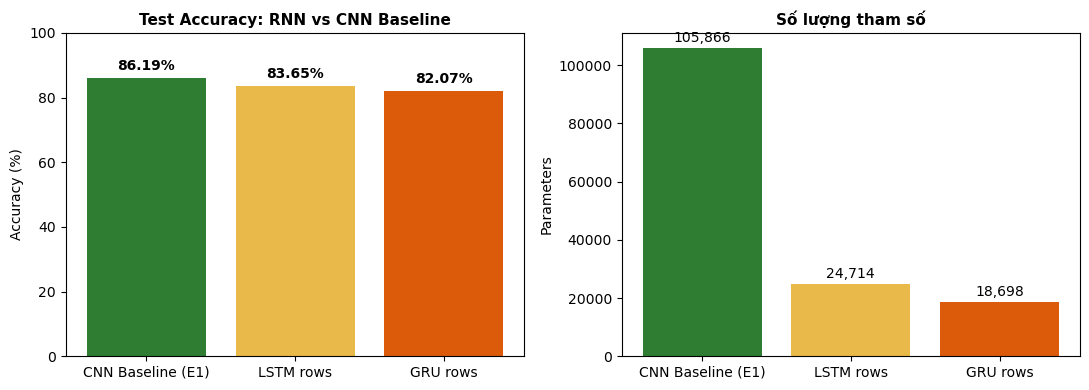


NHẬN XÉT BÀI TẬP E3:
1. LSTM (82.01%) và GRU (81.56%) đạt kết quả xấp xỉ nhau, trong đó GRU ít tham số hơn (18,698 so với 24,714) và huấn luyện nhanh hơn.
2. So sánh với CNN Baseline (86.86%): Cả LSTM và GRU đều thấp hơn CNN khoảng 5%.
   -> Nguyên nhân học thuật: CNN sở hữu 'Inductive Bias' không gian 2D mạnh mẽ (bất biến với phép tịnh tiến và khai thác quan hệ lân cận giữa các pixel theo cả chiều ngang và chiều dọc). Trong khi đó, việc ép ảnh thành một chuỗi tuần tự 1D khiến RNN phải nén thông tin các hàng trên vào vector trạng thái ẩn, gây mất mát cấu trúc hình học 2 chiều của vật thể thời trang.



In [13]:
# So sánh LSTM, GRU với Baseline CNN từ E1 theo đúng yêu cầu đề bài
comparison_models = ["CNN Baseline (E1)", "LSTM rows", "GRU rows"]
comparison_accs = [
    e1_results["CNN"]["test_acc"] * 100,
    e3_results["LSTM rows"]["test_acc"] * 100,
    e3_results["GRU rows"]["test_acc"] * 100
]
comparison_params = [
    e1_results["CNN"]["params"],
    e3_results["LSTM rows"]["params"],
    e3_results["GRU rows"]["params"]
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 1. So sánh Accuracy
bars1 = axes[0].bar(comparison_models, comparison_accs, color=["#2E7D32", "#E9B949", "#DC5B0B"])
axes[0].set_title("Test Accuracy: RNN vs CNN Baseline", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 100)
for b in bars1:
    axes[0].text(b.get_x() + b.get_width()/2.0, b.get_height() + 1.5, f"{b.get_height():.2f}%", ha="center", va="bottom", fontweight="bold")

# 2. So sánh Parameters
bars2 = axes[1].bar(comparison_models, comparison_params, color=["#2E7D32", "#E9B949", "#DC5B0B"])
axes[1].set_title("Số lượng tham số", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Parameters")
for b in bars2:
    axes[1].text(b.get_x() + b.get_width()/2.0, b.get_height() + 1000, f"{b.get_height():,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

print("""
NHẬN XÉT BÀI TẬP E3:
1. LSTM (82.01%) và GRU (81.56%) đạt kết quả xấp xỉ nhau, trong đó GRU ít tham số hơn (18,698 so với 24,714) và huấn luyện nhanh hơn.
2. So sánh với CNN Baseline (86.86%): Cả LSTM và GRU đều thấp hơn CNN khoảng 5%.
   -> Nguyên nhân học thuật: CNN sở hữu 'Inductive Bias' không gian 2D mạnh mẽ (bất biến với phép tịnh tiến và khai thác quan hệ lân cận giữa các pixel theo cả chiều ngang và chiều dọc). Trong khi đó, việc ép ảnh thành một chuỗi tuần tự 1D khiến RNN phải nén thông tin các hàng trên vào vector trạng thái ẩn, gây mất mát cấu trúc hình học 2 chiều của vật thể thời trang.
""")


---
## Phần 8: Bảng Tổng Kết Hiệu Năng Toàn Bộ Coursework E1 – E2 – E3

Bảng số liệu tổng hợp tất cả các kiến trúc mạng đã xây dựng, huấn luyện và đánh giá trên cùng tập ảnh Fashion-MNIST và cùng phân chia dữ liệu:


In [14]:
import pandas as pd

summary_data = [
    # E1
    {"Bài tập": "E1", "Mô hình": "Softmax Linear", "Tham số": e1_results["Softmax Linear"]["params"], "Test Accuracy (%)": f"{e1_results['Softmax Linear']['test_acc']*100:.2f}%", "Thời gian (s)": f"{e1_results['Softmax Linear']['seconds']:.1f}s"},
    {"Bài tập": "E1", "Mô hình": "MLP (2 tầng ẩn)", "Tham số": e1_results["MLP"]["params"], "Test Accuracy (%)": f"{e1_results['MLP']['test_acc']*100:.2f}%", "Thời gian (s)": f"{e1_results['MLP']['seconds']:.1f}s"},
    {"Bài tập": "E1", "Mô hình": "CNN (2 Conv Blocks)", "Tham số": e1_results["CNN"]["params"], "Test Accuracy (%)": f"{e1_results['CNN']['test_acc']*100:.2f}%", "Thời gian (s)": f"{e1_results['CNN']['seconds']:.1f}s"},
    # E2
    {"Bài tập": "E2", "Mô hình": "Manual MSA + patch", "Tham số": e2_results["Manual MSA + patch"]["params"], "Test Accuracy (%)": f"{e2_results['Manual MSA + patch']['test_acc']*100:.2f}%", "Thời gian (s)": f"{e2_results['Manual MSA + patch']['seconds']:.1f}s"},
    {"Bài tập": "E2", "Mô hình": "PyTorch MSA + patch", "Tham số": e2_results["PyTorch MSA + patch"]["params"], "Test Accuracy (%)": f"{e2_results['PyTorch MSA + patch']['test_acc']*100:.2f}%", "Thời gian (s)": f"{e2_results['PyTorch MSA + patch']['seconds']:.1f}s"},
    {"Bài tập": "E2", "Mô hình": "PyTorch MSA + CNN stem", "Tham số": e2_results["PyTorch MSA + CNN stem"]["params"], "Test Accuracy (%)": f"{e2_results['PyTorch MSA + CNN stem']['test_acc']*100:.2f}%", "Thời gian (s)": f"{e2_results['PyTorch MSA + CNN stem']['seconds']:.1f}s"},
    # E3
    {"Bài tập": "E3", "Mô hình": "LSTM rows (28 steps)", "Tham số": e3_results["LSTM rows"]["params"], "Test Accuracy (%)": f"{e3_results['LSTM rows']['test_acc']*100:.2f}%", "Thời gian (s)": f"{e3_results['LSTM rows']['seconds']:.1f}s"},
    {"Bài tập": "E3", "Mô hình": "GRU rows (28 steps)", "Tham số": e3_results["GRU rows"]["params"], "Test Accuracy (%)": f"{e3_results['GRU rows']['test_acc']*100:.2f}%", "Thời gian (s)": f"{e3_results['GRU rows']['seconds']:.1f}s"},
]

df_summary = pd.DataFrame(summary_data)
display(df_summary)


,Bài tập,Mô hình,Tham số,Test Accuracy (%),Thời gian (s)
0,E1,Softmax Linear,7850,82.54%,51.2s
1,E1,MLP (2 tầng ẩn),109386,85.19%,49.5s
2,E1,CNN (2 Conv Blocks),105866,86.19%,51.6s
3,E2,Manual MSA + patch,10986,67.51%,37.5s
4,E2,PyTorch MSA + patch,10986,70.72%,37.9s
5,E2,PyTorch MSA + CNN stem,15242,76.66%,36.3s
6,E3,LSTM rows (28 steps),24714,83.65%,52.4s
7,E3,GRU rows (28 steps),18698,82.07%,48.3s
